In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
csv_path = '/home/amir/open_face/videos/openface_marisa/236/236_Emotions_marissa.csv'
df = pd.read_csv(csv_path)

In [3]:
def plot_au12_au06(df, start_time, end_time):
    df_filtered = df[(df['timestamp'] >= start_time) & (df['timestamp'] <= end_time)].copy()
    # 5. Set up the figure
    fig, axs = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
    axs = axs.flatten()
    # --- Plot 1: AU12_r (Smile Intensity) ---
    axs[0].plot(df_filtered['timestamp'], df_filtered['AU12_r'], color='blue', label='AU12_r (Intensity)')
    axs[0].set_title('AU12 (Smile) - Intensity & Presence')
    axs[0].set_ylabel('Intensity (0-5)')
    axs[0].legend(loc='upper right')
    axs[0].grid(True, alpha=0.3)

    # --- Plot 2: AU12_c (Smile Presence) ---
    axs[1].plot(df_filtered['timestamp'], df_filtered['AU12_c'], color='cyan', label='AU12_c (Binary)')
    axs[1].set_ylabel('Presence (0 or 1)')
    axs[1].legend(loc='upper right')
    axs[1].grid(True, alpha=0.3)

    # --- Plot 3 & 4: AU06_r and AU06_c ---
    if 'AU06_r' in df_filtered.columns and 'AU06_c' in df_filtered.columns:
        
        # Plot AU06_r
        axs[2].plot(df_filtered['timestamp'], df_filtered['AU06_r'], color='red', label='AU06_r (Intensity)')
        axs[2].set_title('AU06 (Cheek Raiser) - Intensity & Presence')
        axs[2].set_ylabel('Intensity (0-5)')
        axs[2].legend(loc='upper right')
        axs[2].grid(True, alpha=0.3)

        # Plot AU06_c
        axs[3].plot(df_filtered['timestamp'], df_filtered['AU06_c'], color='orange', label='AU06_c (Binary)')
        axs[3].set_ylabel('Presence (0 or 1)')
        axs[3].legend(loc='upper right')
        axs[3].grid(True, alpha=0.3)

    else:
        # If AU06 is missing, display a message
        axs[2].text(0.5, 0.5, 'AU06_r column not found', ha='center', va='center', fontsize=12)
        axs[3].text(0.5, 0.5, 'AU06_c column not found', ha='center', va='center', fontsize=12)

    # Format the final layout dynamically based on your variables
    plt.xlim(start_time, end_time) 
    axs[3].set_xlabel('Timestamp (seconds)')
    plt.tight_layout()

    # Display the plot
    plt.show()

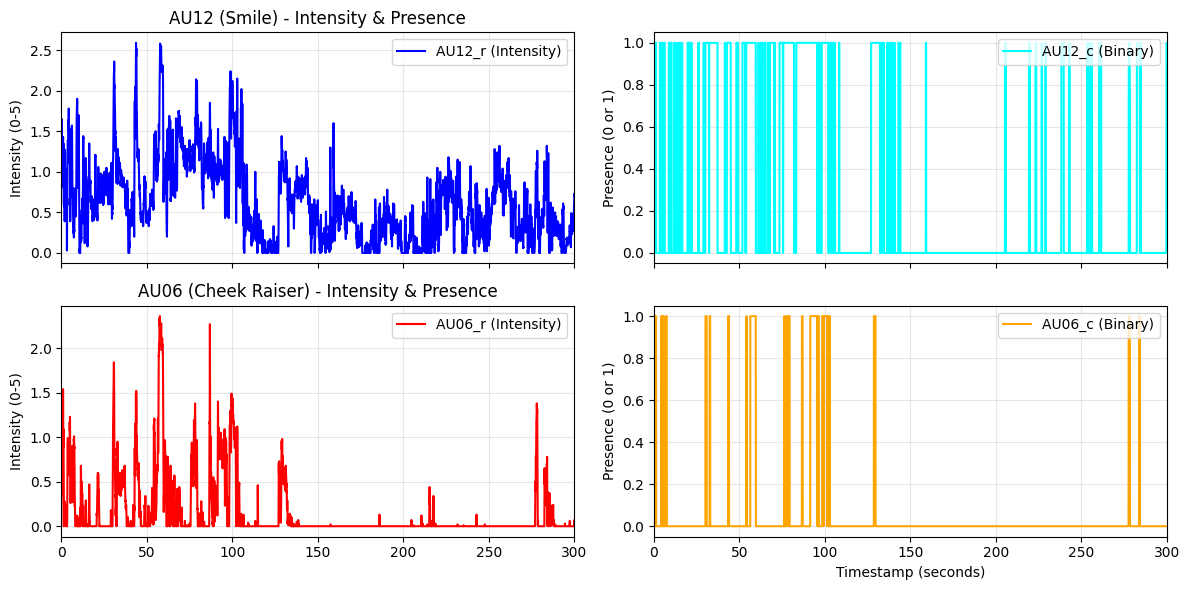

In [4]:
plot_au12_au06(df, start_time=0, end_time=300)

In [5]:
# =========================================================
# SET YOUR DESIRED START AND END TIMES HERE (in seconds)
start_time = 0.0  
end_time = 50.0    
# =========================================================


# Filter data to your chosen time window
df_filtered = df[(df['timestamp'] >= start_time) & (df['timestamp'] <= end_time)].copy()


In [6]:
signal_12 = df_filtered['AU12_r'].values
signal_06 = df_filtered['AU06_r'].values

In [7]:
def get_intervals(timestamps, signal, threshold):
    # Convert signal to a simple 0 (below) or 1 (above) array
    is_above = (signal >= threshold).astype(int)
    
    # +1 means it crossed UP, -1 means it crossed DOWN
    diffs = np.diff(is_above)
    
    # Find where the signal crosses the threshold +1 because diff operator reduces length by 1
    start_idx = np.where(diffs == 1)[0] + 1
    end_idx = np.where(diffs == -1)[0] + 1
    
    # Edge case 1: The signal started already above the threshold
    if is_above[0] == 1:
        start_idx = np.insert(start_idx, 0, 0)
        
    # Edge case 2: The signal ended while still above the threshold
    if is_above[-1] == 1:
        end_idx = np.append(end_idx, len(signal) - 1)
        
    # Map the indices back to the actual timestamp values
    starts = timestamps.iloc[start_idx].values
    ends = timestamps.iloc[end_idx].values
    
    return list(zip(starts, ends))

In [8]:
def print_intervals(au12_intervals, au06_intervals, threshold):
    print(f"Results for timeframe {start_time}s to {end_time}s (Threshold: {threshold}):\n")
    print("--- AU12 (Smile) Intervals ---")
    if len(au12_intervals) == 0:
        print("No smiles detected.")
    for start, end in au12_intervals:
        print(f"Start: {start:.2f}s  ->  End: {end:.2f}s  (Duration: {end-start:.2f}s)")

    print("\n--- AU06 (Cheek Raiser) Intervals ---")
    if len(au06_intervals) == 0:
        print("No cheek raises detected.")
    for start, end in au06_intervals:
        print(f"Start: {start:.2f}s  ->  End: {end:.2f}s  (Duration: {end-start:.2f}s)")

In [9]:
# Define the threshold for the continuous signals
threshold = 1.5
au12_intervals = get_intervals(df_filtered['timestamp'], signal_12, threshold)
au06_intervals = get_intervals(df_filtered['timestamp'], signal_06, threshold)
print_intervals(au12_intervals, au06_intervals, threshold)

Results for timeframe 0.0s to 50.0s (Threshold: 1.5):

--- AU12 (Smile) Intervals ---
Start: 0.10s  ->  End: 0.27s  (Duration: 0.17s)
Start: 4.10s  ->  End: 4.43s  (Duration: 0.33s)
Start: 5.07s  ->  End: 5.10s  (Duration: 0.03s)
Start: 6.13s  ->  End: 6.30s  (Duration: 0.17s)
Start: 8.93s  ->  End: 9.43s  (Duration: 0.50s)
Start: 10.03s  ->  End: 10.27s  (Duration: 0.23s)
Start: 30.50s  ->  End: 31.63s  (Duration: 1.13s)
Start: 31.67s  ->  End: 31.70s  (Duration: 0.03s)
Start: 42.83s  ->  End: 43.10s  (Duration: 0.27s)
Start: 43.13s  ->  End: 44.37s  (Duration: 1.23s)

--- AU06 (Cheek Raiser) Intervals ---
Start: 0.87s  ->  End: 0.93s  (Duration: 0.07s)
Start: 1.03s  ->  End: 1.10s  (Duration: 0.07s)
Start: 30.53s  ->  End: 30.93s  (Duration: 0.40s)
Start: 43.83s  ->  End: 43.87s  (Duration: 0.03s)


In [10]:
df_filtered['AU12_shifted'] = df_filtered['AU12_r'] - threshold
df_filtered['AU06_shifted'] = df_filtered['AU06_r'] - threshold

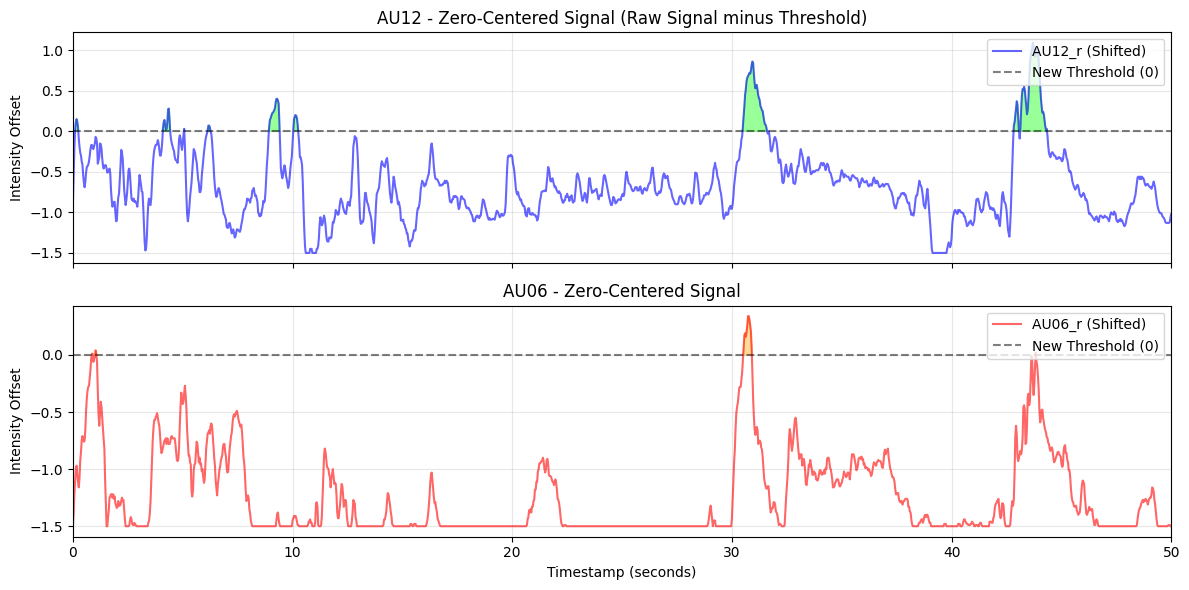

In [11]:

fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# ---------------------------------------------------------
# AU12 (Smile) - Shifted Plot
# ---------------------------------------------------------
axs[0].plot(df_filtered['timestamp'], df_filtered['AU12_shifted'], color='blue', alpha=0.6, label='AU12_r (Shifted)')

# Draw the new threshold line at exactly ZERO
axs[0].axhline(0, color='black', linestyle='--', alpha=0.5, label='New Threshold (0)')

# Magically fill the area only WHERE the signal is > 0
axs[0].fill_between(df_filtered['timestamp'], 
                    df_filtered['AU12_shifted'], 
                    0,  # Fill down to the zero line
                    where=(df_filtered['AU12_shifted'] >= 0), 
                    color='lime', alpha=0.4, interpolate=True)

axs[0].set_title('AU12 - Zero-Centered Signal (Raw Signal minus Threshold)')
axs[0].set_ylabel('Intensity Offset')
axs[0].legend(loc='upper right')
axs[0].grid(True, alpha=0.3)

# ---------------------------------------------------------
# AU06 (Cheek Raiser) - Shifted Plot
# ---------------------------------------------------------
if 'AU06_r' in df_filtered.columns:
    axs[1].plot(df_filtered['timestamp'], df_filtered['AU06_shifted'], color='red', alpha=0.6, label='AU06_r (Shifted)')
    
    # Draw the new threshold line at exactly ZERO
    axs[1].axhline(0, color='black', linestyle='--', alpha=0.5, label='New Threshold (0)')

    # Magically fill the area only WHERE the signal is > 0
    axs[1].fill_between(df_filtered['timestamp'], 
                        df_filtered['AU06_shifted'], 
                        0, 
                        where=(df_filtered['AU06_shifted'] >= 0), 
                        color='orange', alpha=0.4, interpolate=True)

    axs[1].set_title('AU06 - Zero-Centered Signal')
    axs[1].set_ylabel('Intensity Offset')
    axs[1].legend(loc='upper right')
    axs[1].grid(True, alpha=0.3)
else:
    axs[1].text(0.5, 0.5, 'AU06_r column not found', ha='center', va='center', fontsize=12)

# Format layout
plt.xlim(start_time, end_time) 
axs[1].set_xlabel('Timestamp (seconds)')
plt.tight_layout()

# Display the plot
plt.show()

In [12]:
print("--- AU12 (Smile) Energy (Integral) ---")
au12_energy_results = {'starts': [], 'durations': [], 'areas': []}
au06_energy_results = {'starts': [], 'durations': [], 'areas': []}
if len(au12_intervals) == 0:
    print("No smiles detected.")
else:
    for i, (start, end) in enumerate(au12_intervals):
        # 1. Isolate the data for this specific smile
        mask = (df_filtered['timestamp'] >= start) & (df_filtered['timestamp'] <= end)
        
        # 2. Extract X (Time) and Y (Shifted Intensity)
        x_time = df_filtered['timestamp'][mask].values
        y_intensity = df_filtered['AU12_shifted'][mask].values
        
        # 3. Calculate the integral using the Trapezoidal Rule
        # Note: In newer versions of NumPy (2.0+), np.trapz is renamed to np.trapezoid
        try:
            area = np.trapezoid(y_intensity, x_time) 
        except AttributeError:
            area = np.trapz(y_intensity, x_time) # Fallback for older NumPy versions

        au12_energy_results['starts'].append(start)
        au12_energy_results['durations'].append(end - start)
        au12_energy_results['areas'].append(area)
        print(f"Smile {i+1}: Start: {start:.2f}s | End: {end:.2f}s | Duration: {au12_energy_results['durations'][-1]:.2f}s | Total Energy (AUC): {area:.3f}")

print("\n--- AU06 (Cheek Raiser) Energy (Integral) ---")
if len(au06_intervals) == 0:
    print("No cheek raises detected.")
else:
    for i, (start, end) in enumerate(au06_intervals):
        mask = (df_filtered['timestamp'] >= start) & (df_filtered['timestamp'] <= end)
        x_time = df_filtered['timestamp'][mask].values
        y_intensity = df_filtered['AU06_shifted'][mask].values
        
        try:
            area = np.trapezoid(y_intensity, x_time)
        except AttributeError:
            area = np.trapz(y_intensity, x_time)
            
        au06_energy_results['starts'].append(start)
        au06_energy_results['durations'].append(end - start)
        au06_energy_results['areas'].append(area)
        print(f"Cheek Raise {i+1}: Start: {start:.2f}s | End: {end:.2f}s | Duration: {au06_energy_results['durations'][-1]:.2f}s | Total Energy (AUC): {area:.3f}")

--- AU12 (Smile) Energy (Integral) ---
Smile 1: Start: 0.10s | End: 0.27s | Duration: 0.17s | Total Energy (AUC): 0.013
Smile 2: Start: 4.10s | End: 4.43s | Duration: 0.33s | Total Energy (AUC): 0.040
Smile 3: Start: 5.07s | End: 5.10s | Duration: 0.03s | Total Energy (AUC): -0.003
Smile 4: Start: 6.13s | End: 6.30s | Duration: 0.17s | Total Energy (AUC): 0.006
Smile 5: Start: 8.93s | End: 9.43s | Duration: 0.50s | Total Energy (AUC): 0.122
Smile 6: Start: 10.03s | End: 10.27s | Duration: 0.23s | Total Energy (AUC): 0.032
Smile 7: Start: 30.50s | End: 31.63s | Duration: 1.13s | Total Energy (AUC): 0.507
Smile 8: Start: 31.67s | End: 31.70s | Duration: 0.03s | Total Energy (AUC): -0.000
Smile 9: Start: 42.83s | End: 43.10s | Duration: 0.27s | Total Energy (AUC): 0.048
Smile 10: Start: 43.13s | End: 44.37s | Duration: 1.23s | Total Energy (AUC): 0.687

--- AU06 (Cheek Raiser) Energy (Integral) ---
Cheek Raise 1: Start: 0.87s | End: 0.93s | Duration: 0.07s | Total Energy (AUC): -0.000
Che

In [13]:
# Calculate for AU12
au12_starts, au12_widths, au12_areas = au12_energy_results['starts'], au12_energy_results['durations'], au12_energy_results['areas']
au06_starts, au06_widths, au06_areas = au06_energy_results['starts'], au06_energy_results['durations'], au06_energy_results['areas']


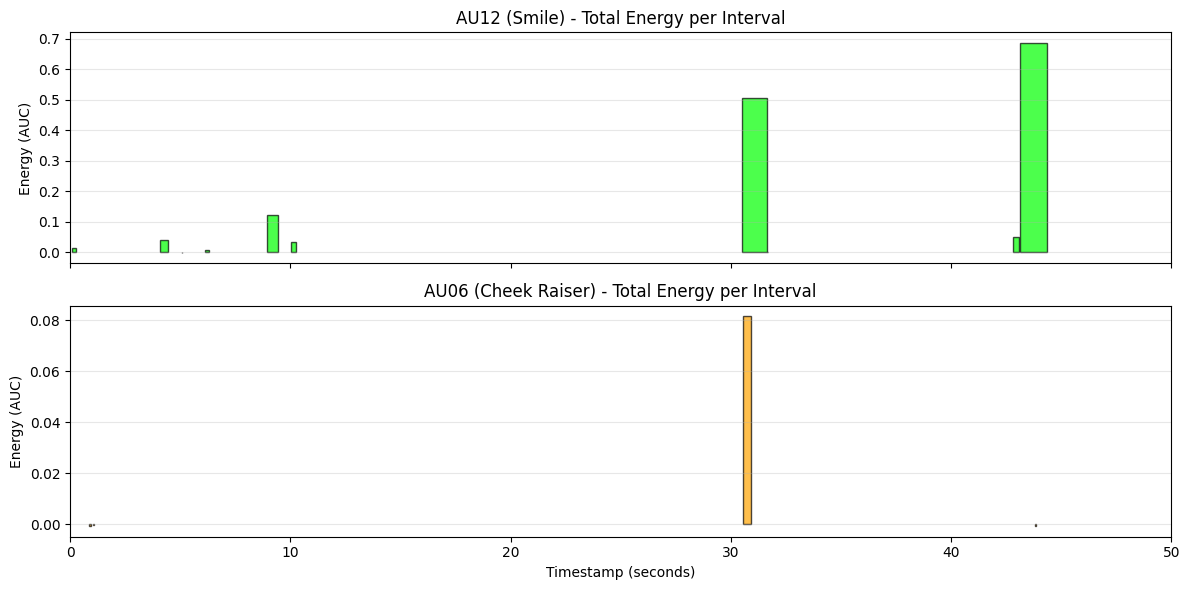

In [14]:
# =========================================================
# 2. PLOT THE ENERGY HISTOGRAMS (BAR CHARTS)
# =========================================================
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# --- AU12 (Smile) ---
if len(au12_starts) > 0:
    axs[0].bar(au12_starts, au12_areas, width=au12_widths, align='edge', 
               color='lime', edgecolor='black', alpha=0.7)
axs[0].set_title('AU12 (Smile) - Total Energy per Interval')
axs[0].set_ylabel('Energy (AUC)')
axs[0].grid(axis='y', alpha=0.3)

# --- AU06 (Cheek Raiser) ---
if len(au06_starts) > 0:
    axs[1].bar(au06_starts, au06_areas, width=au06_widths, align='edge', 
               color='orange', edgecolor='black', alpha=0.7)
    axs[1].set_title('AU06 (Cheek Raiser) - Total Energy per Interval')
else:
    axs[1].set_title('AU06 (Cheek Raiser) - No Expressions Detected')
    
axs[1].set_ylabel('Energy (AUC)')
axs[1].grid(axis='y', alpha=0.3)

# Format layout to match your existing timeline
plt.xlim(df_filtered['timestamp'].min(), df_filtered['timestamp'].max()) 
axs[1].set_xlabel('Timestamp (seconds)')
plt.tight_layout()
plt.show()

In [15]:
sign_au12 = np.sign(df_filtered['AU12_shifted']) 
sign_au06 = np.sign(df_filtered['AU06_shifted'])

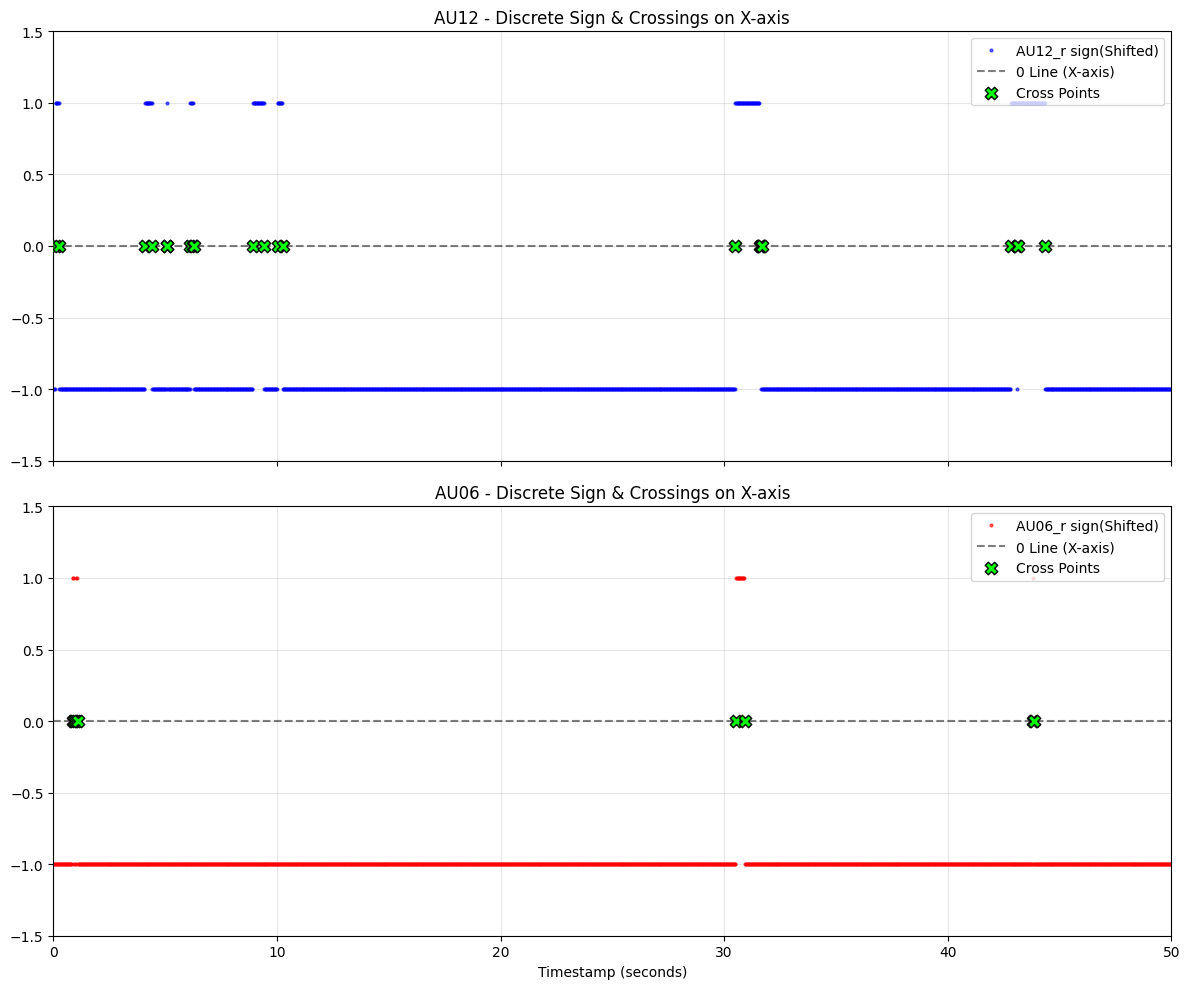

In [16]:
# 1. Create a new figure with 2 subplots
fig, axs = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

crossings_12_idx = np.where(np.diff(np.sign(signal_12 - threshold)))[0]
crossings_12_idx += 1 
cross_points_12 = df_filtered.iloc[crossings_12_idx]

# Plot Discrete Sign Signal
axs[0].plot(df_filtered['timestamp'], sign_au12, color='blue', alpha=0.6, 
            label='AU12_r sign(Shifted)', linestyle='none', marker='.', markersize=4)

axs[0].axhline(0, color='black', linestyle='--', alpha=0.5, label='0 Line (X-axis)')

# Plot Crossing Points on the X-axis (y=0)
axs[0].scatter(cross_points_12['timestamp'], np.zeros(len(cross_points_12)), 
               color='lime', marker='X', s=80, edgecolor='black', label='Cross Points', zorder=5)

axs[0].set_title('AU12 - Discrete Sign & Crossings on X-axis')
axs[0].set_ylim(-1.5, 1.5) # Give the +/- 1 dots some breathing room
axs[0].legend(loc='upper right')
axs[0].grid(True, alpha=0.3)

# ---------------------------------------------------------
# AU06 (Cheek Raiser)
# ---------------------------------------------------------
crossings_06_idx = np.where(np.diff(np.sign(signal_06 - threshold)))[0]
crossings_06_idx += 1
cross_points_06 = df_filtered.iloc[crossings_06_idx]

# Plot Discrete Sign Signal
axs[1].plot(df_filtered['timestamp'], sign_au06, color='red', alpha=0.6, 
            label='AU06_r sign(Shifted)', linestyle='none', marker='.', markersize=4)

axs[1].axhline(0, color='black', linestyle='--', alpha=0.5, label='0 Line (X-axis)')

# Plot Crossing Points on the X-axis (y=0)
axs[1].scatter(cross_points_06['timestamp'], np.zeros(len(cross_points_06)), 
               color='lime', marker='X', s=80, edgecolor='black', label='Cross Points', zorder=5)

axs[1].set_title('AU06 - Discrete Sign & Crossings on X-axis')
axs[1].set_ylim(-1.5, 1.5)
axs[1].legend(loc='upper right')
axs[1].grid(True, alpha=0.3)
axs[1].set_xlabel('Timestamp (seconds)')

# ---------------------------------------------------------
# Formatting
# ---------------------------------------------------------
plt.xlim(start_time, end_time) 
plt.tight_layout()
plt.show()

In [17]:
au12_intervals = get_intervals(df_filtered['timestamp'], df_filtered['AU12_r'].values, threshold)
au06_intervals = get_intervals(df_filtered['timestamp'], df_filtered['AU06_r'].values, threshold)

In [18]:
# Set your thresholds (Number of FRAMES)
thresholdup = 15   
thresholddown = 15 

time_array = df_filtered['timestamp'].values
sign_array = sign_au12.values

validated_intervals = []

# ---> NEW: Memory variable to track where the last event ended
last_valid_end_time = -1.0 

for start, original_end in au12_intervals:
    
    # ---> NEW: If this start is behind the end of the last closed event, skip it!
    if start <= last_valid_end_time:
        continue
        
    # 1. Find the exact INDEX
    begin_idx = np.where(time_array == start)[0][0]
    
    hot_up = 0
    hot_down = 0
    is_valid_event = False
    
    current_idx = begin_idx
    
    # 2. Iterate forward frame-by-frame
    while current_idx < len(sign_array):
        
        if sign_array[current_idx] >= 0:
            hot_up += 1
            hot_down = 0 
            if hot_up >= thresholdup:
                is_valid_event = True
                
        else:
            hot_down += 1
            if hot_down >= thresholddown:
                break 
                
        current_idx += 1
        
    # 3. If it passed, record it and update our memory!
    if is_valid_event:
        true_end_idx = current_idx - hot_down
        true_end_time = time_array[true_end_idx]
        
        validated_intervals.append((time_array[begin_idx], true_end_time))
        
        # ---> NEW: Update the memory so the next loop knows where this ended
        last_valid_end_time = true_end_time

# Print the results
print(f"Found {len(validated_intervals)} validated smiles:")
for s, e in validated_intervals:
    print(f"Start: {s:.4f}s  ->  End: {e:.4f}s")

Found 3 validated smiles:
Start: 8.9330s  ->  End: 9.4000s
Start: 30.5000s  ->  End: 31.6670s
Start: 42.8330s  ->  End: 44.3330s


In [19]:
from functools import reduce

intervals = get_intervals(df_filtered['timestamp'], df_filtered['AU12_r'].values, threshold)
margin = 0.1


merged = reduce(lambda r, i: r[:-1] + [(r[-1][0], max(r[-1][1], i[1]))] if i[0] - r[-1][1] <= margin else r + [i], sorted(intervals)[1:], [sorted(intervals)[0]]) if intervals else []

print(merged)

[(np.float64(0.1), np.float64(0.267)), (np.float64(4.1), np.float64(4.433)), (np.float64(5.067), np.float64(5.1)), (np.float64(6.133), np.float64(6.3)), (np.float64(8.933), np.float64(9.433)), (np.float64(10.033), np.float64(10.267)), (np.float64(30.5), np.float64(31.7)), (np.float64(42.833), np.float64(44.367))]


In [20]:
# video 236 
#ground_truth_events = [(30, 31), (32, 33), (42, 44)
#                       (55, 59), (1:26, 1:27), (1:31, 1:32)
#                       (1:38, 1:39), (4:42, 4:44), (5:23, 5:25),
#                       (6:39, 6:40)]

# Video 236 Ground Truth Events (Converted to total seconds)
ground_truth_events = [
    (30.0, 31.0),
    (32.0, 33.0),
    (42.0, 44.0),
    (55.0, 59.0),
    (86.0, 87.0),    # Originally 1:26 - 1:27
    (91.0, 92.0),    # Originally 1:31 - 1:32
    (98.0, 99.0),    # Originally 1:38 - 1:39
    (282.0, 284.0),  # Originally 4:42 - 4:44
    (323.0, 325.0),  # Originally 5:23 - 5:25
    (399.0, 400.0)   # Originally 6:39 - 6:40
]

In [21]:
# =========================================================
# 1. DEFINE THE PLOTTING FUNCTION
# =========================================================
def plot_ground_truth_slice(df, ground_truth, start_time=None, end_time=None):
    # If no start/end is provided, use the whole video
    if start_time is None:
        start_time = df['timestamp'].min()
    if end_time is None:
        end_time = df['timestamp'].max()

    # Slice the dataframe to the requested time window
    df_slice = df[(df['timestamp'] >= start_time) & (df['timestamp'] <= end_time)].copy()
    
    if df_slice.empty:
        print(f"No data found between {start_time}s and {end_time}s!")
        return

    # Setup the figure
    fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    timestamps = df_slice['timestamp']

    # ---------------------------------------------------------
    # AU12 (Smile) Plot
    # ---------------------------------------------------------
    axs[0].plot(timestamps, df_slice['AU12_r'], color='blue', alpha=0.8, label='AU12_r Signal')
    
    # Add the Ground Truth highlighting blocks
    added_label = False
    for gt_start, gt_end in ground_truth:
        # Only add the legend label once to avoid clutter
        label = 'Ground Truth (Human)' if not added_label else ""
        axs[0].axvspan(gt_start, gt_end, color='lime', alpha=0.25, label=label)
        added_label = True

    axs[0].set_title('AU12_r vs. Ground Truth Annotations')
    axs[0].set_ylabel('Intensity')
    axs[0].legend(loc='upper right')
    axs[0].grid(True, alpha=0.3)

    # ---------------------------------------------------------
    # AU06 (Cheek Raiser) Plot
    # ---------------------------------------------------------
    if 'AU06_r' in df_slice.columns:
        axs[1].plot(timestamps, df_slice['AU06_r'], color='red', alpha=0.8, label='AU06_r Signal')
        
        # Add the Ground Truth highlighting blocks
        added_label = False
        for gt_start, gt_end in ground_truth:
            label = 'Ground Truth (Human)' if not added_label else ""
            axs[1].axvspan(gt_start, gt_end, color='lime', alpha=0.25, label=label)
            added_label = True

        axs[1].set_title('AU06_r vs. Ground Truth Annotations')
        axs[1].set_ylabel('Intensity')
        axs[1].legend(loc='upper right')
        axs[1].grid(True, alpha=0.3)
    else:
        axs[1].text(0.5, 0.5, 'AU06_r column not found', ha='center', va='center', fontsize=12)

    # Format layout tightly around your requested cut
    plt.xlim(start_time, end_time)
    axs[1].set_xlabel('Timestamp (seconds)')
    plt.tight_layout()
    plt.show()


Plotting a specific cut of the video:


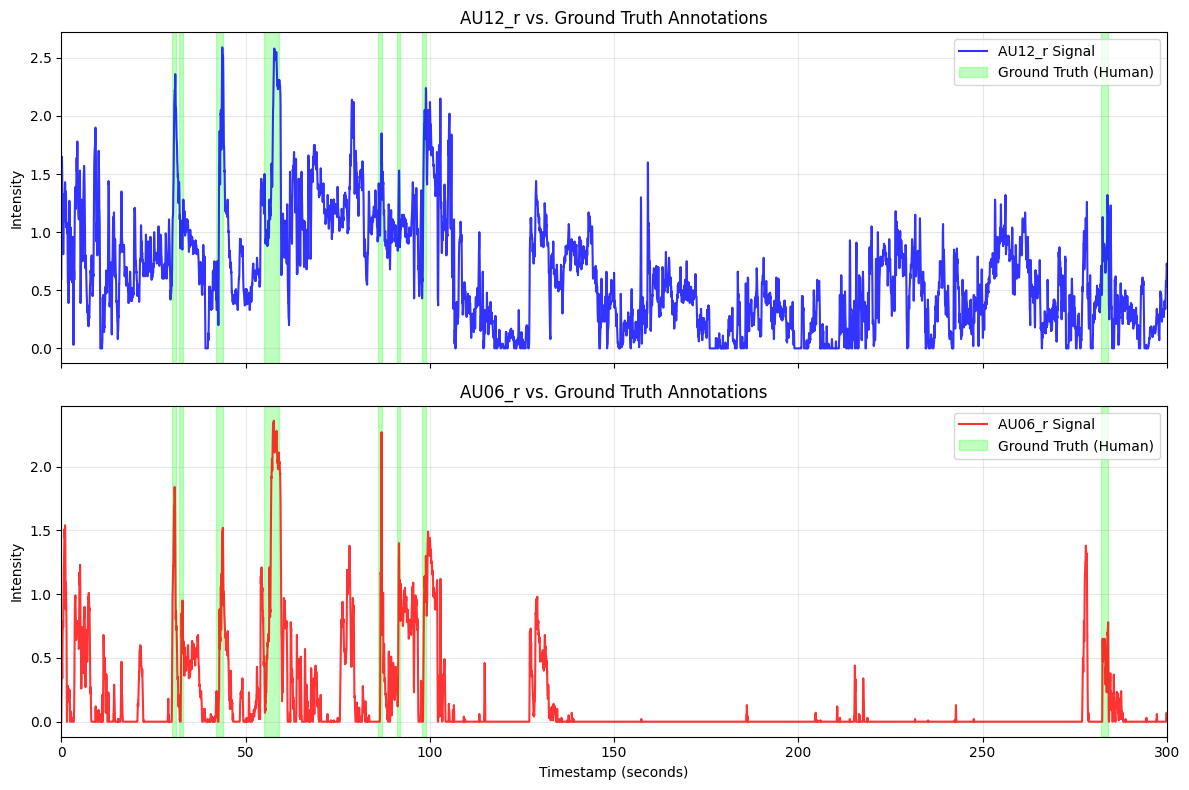

In [22]:
# Example 1: View just a specific slice (e.g., 80s to 105s)
print("Plotting a specific cut of the video:")
plot_ground_truth_slice(df, ground_truth_events, start_time=0.0, end_time=300.0)

# Example 2: To view the whole video at once, just leave the times blank!
# plot_ground_truth_slice(df, ground_truth_events)